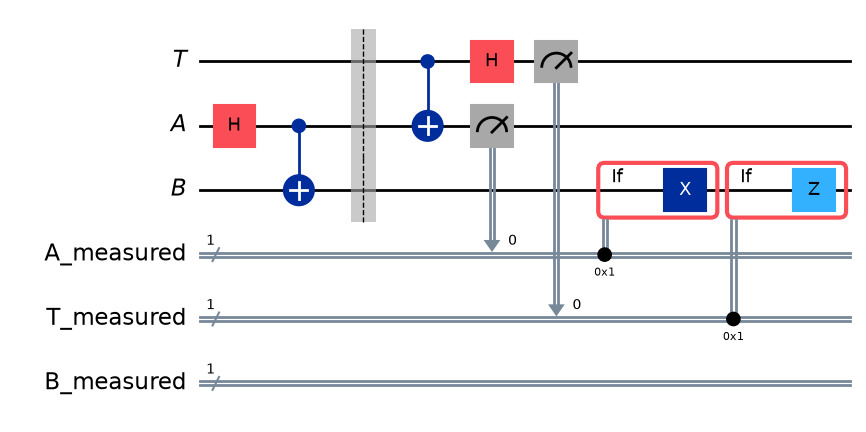

In [18]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from matplotlib import pyplot as plt

# Creates quantum particles.
qr_A = QuantumRegister(1, "A")
qr_T = QuantumRegister(1, "T")
qr_B = QuantumRegister(1, "B")

qregs = [qr_T, qr_A, qr_B]
# Creates classical placeholders for measurements.
regA_result = ClassicalRegister(1, "A_measured")
regT_result = ClassicalRegister(1, "T_measured")
regB_result = ClassicalRegister(1, "B_measured")

circuit = QuantumCircuit(*qregs, regA_result, regT_result, regB_result)

# Creates Bell Pair between A and B.
circuit.h(qr_A)
circuit.cx(qr_A, qr_B)
circuit.barrier() # Visual separator

# Quantum teleportation circuit.
circuit.cx(0, 1)
circuit.h(0)
circuit.measure(qr_T, regT_result)
circuit.measure(qr_A, regA_result)

with circuit.if_test((regA_result, 1)):
    circuit.x(qr_B)

with circuit.if_test((regT_result, 1)):
    circuit.z(qr_B)

# Return a drawing of the circuit using MatPlotLib ("mpl").
circuit.draw("mpl")

In [20]:
# Measure B via simulation.
circuit.measure(qr_B, regB_result)
simulator = AerSimulator()
compiled_circuit = transpile(circuit, simulator)

# Use 1000 attempts (expecting largely equal numbers of each outcome).
job = simulator.run(compiled_circuit, shots=1000)
counts = job.result().get_counts()

print("Measurement Counts:", counts)

Measurement Counts: {'0 0 1': 221, '0 0 0': 252, '0 1 0': 260, '0 1 1': 267}
